In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torchinfo
from datasets import Dataset, load_dataset
from torch import nn, optim
from torch.utils.data import DataLoader
from torchmetrics.text import Perplexity

import torchtext.transforms as T
from torchlake.common.controller.evaluator import RegressionEvaluator
from torchlake.common.controller.recorder import TrainRecorder
from torchlake.common.controller.trainer import ClassificationTrainer
from torchlake.common.controller.weight_manager import WeightManager
from torchlake.common.schemas.nlp import NLPContext
from torchlake.common.utils.platform import get_num_workers
from torchlake.common.utils.text import build_vocab, is_corpus_title, is_longer_text
from torchlake.language_model.models.gate_conv import GatedConvLM
from torchtext.data.utils import get_tokenizer

d:\research\pytorch-implementations\gits\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
torch.__version__

'2.8.0+cu126'

# setting


In [5]:
DATASET_NAME = "wikitext-2-raw-v1"
# DATASET_NAME = "wikitext-103-raw-v1"

In [6]:
artifact_path = Path("../../artifacts/gated_conv")
artifact_path.mkdir(exist_ok=True)

artifact_dataset_path = artifact_path / DATASET_NAME
artifact_dataset_path.mkdir(exist_ok=True)

data_path = Path("../../data/hf")

In [7]:
CONTEXT = NLPContext()

In [8]:
BATCH_SIZE = 32
MINIMUM_LENGTH = 5

In [9]:
DEVICE = torch.device(CONTEXT.device)

In [10]:
NUM_WORKERS = get_num_workers()

In [11]:
tokenizer = get_tokenizer("basic_english")

# data

In [12]:
def dataset_factory(
    dataset: Dataset,
    minimum_length: int = 1,
    transform=None,
):
    dataset = (
        dataset.map(lambda pair: {"text": pair["text"].strip()})
        .map(lambda pair: {"text": pair["text"].lower()})
        .filter(lambda pair: is_longer_text(pair["text"], minimum_length))
        .filter(lambda pair: not is_corpus_title(pair["text"]))
        .map(lambda pair: {"text": tokenizer(pair["text"])})
    )

    if transform:
        dataset = dataset.map(lambda pair: {"text": transform(pair["text"])})

    return dataset

In [13]:
train_dataset = load_dataset(
    "Salesforce/wikitext", name=DATASET_NAME, cache_dir=data_path, split="train"
)

In [14]:
vocab = build_vocab(
    map(lambda x: x["text"], dataset_factory(train_dataset, MINIMUM_LENGTH)),
    context=CONTEXT,
)

In [15]:
VOCAB_SIZE = len(vocab)
VOCAB_SIZE

20827

In [16]:
# write_json_file(
#     artifact_dataset_path.joinpath("vocab.json"),
#     list(vocab.get_stoi().keys()),
# )

In [17]:
vocab.lookup_tokens(range(20))

['<unk>',
 '<bos>',
 '<eos>',
 '<pad>',
 'the',
 ',',
 '.',
 'of',
 'and',
 'in',
 'to',
 'a',
 'was',
 "'",
 '@-@',
 'on',
 'as',
 's',
 'that',
 'for']

In [18]:
text_transform = T.Sequential(
    T.VocabTransform(vocab),
    T.AddToken(token=CONTEXT.bos_idx, begin=True),
    T.AddToken(token=CONTEXT.eos_idx, begin=False),
    T.Truncate(CONTEXT.max_seq_len),
    T.ToTensor(),
    T.PadTransform(CONTEXT.max_seq_len, CONTEXT.padding_idx),
)

In [19]:
train_dataset = dataset_factory(
    train_dataset,
    MINIMUM_LENGTH,
    text_transform,
)

In [20]:
def collate_fn(batch):
    placeholders = []
    for it in batch:
        placeholders.append(it["text"])

    return (
        torch.stack(placeholders, 0)[:, :-1],
        torch.stack(placeholders, 0)[:, 1:],
    )

In [21]:
train_dataloader = DataLoader(
    train_dataset.with_format("torch"),
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    shuffle=True,
    drop_last=True,
    collate_fn=collate_fn,
)

In [22]:
for prev, next in train_dataloader:
    print(prev.shape, next.shape)
    break

torch.Size([32, 255]) torch.Size([32, 255])


### word freq

In [1]:
from torchlake.common.utils.text import get_unigram_counts

In [ ]:
word_freqs = get_unigram_counts(
    map(lambda x: x["text"].tolist(), train_dataset.with_format("torch")),
    VOCAB_SIZE,
    freq=False,
)

In [ ]:
word_freqs.argsort()

tensor([17119, 18746, 19964,  ...,     5,     4,     3])

In [ ]:
vocab

# model

In [21]:
EMBED_DIM = 256

In [22]:
model = GatedConvLM(
    VOCAB_SIZE,
    EMBED_DIM,
    key="8",
    context=CONTEXT,
).to(DEVICE)

In [23]:
torchinfo.summary(model)

Layer (type:depth-idx)                                                                Param #
GatedConvLM                                                                           --
├─Embedding: 1-1                                                                      5,331,712
├─Sequential: 1-2                                                                     --
│    └─ResBlock: 2-1                                                                  --
│    │    └─ReLU: 3-1                                                                 --
│    │    └─BottleNeck: 3-2                                                           1,846,800
│    │    └─Sequential: 3-3                                                           232,200
│    └─ResBlock: 2-2                                                                  --
│    │    └─ReLU: 3-4                                                                 --
│    │    └─BottleNeck: 3-5                                                           

# training


In [24]:
EPOCHS = 5

In [25]:
trainer = ClassificationTrainer(EPOCHS, DEVICE, feature_last=False)

In [26]:
recorder = TrainRecorder(total_epoch=EPOCHS)
recorder.increment_dataset_size(len(train_dataset))

In [ ]:
criterion = nn.CrossEntropyLoss(
    ignore_index=CONTEXT.padding_idx,
    reduction="mean",
)
# criterion = nn.AdaptiveLogSoftmaxWithLoss(
#     VOCAB_SIZE,
#     VOCAB_SIZE,
#     (2000, 10000, 50000),
#     device=DEVICE,
# )
optimizer = optim.Adam(model.parameters(), lr=1e-3)  # no luck to increase lr

In [28]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    "min",
    patience=5,
    threshold=0.05,
    threshold_mode="rel",
)

In [ ]:
training_loss = trainer.run(
    train_dataloader,
    model,
    optimizer,
    criterion,
    scheduler=scheduler,
    recorder=recorder,
    # gradient_clipping_hook=lambda: nn.utils.clip_grad_norm_(model.parameters(), 1), # no luck
)

Enable AMP: False
Training...


100%|██████████| 545/545 [01:58<00:00,  4.59it/s]


------------------------------------
Epoch 1
------------------------------------
total: 2.0014e-01 (0.00%)


100%|██████████| 545/545 [01:58<00:00,  4.59it/s]


------------------------------------
Epoch 2
------------------------------------
total: 1.6739e-01 (-16.00%)


100%|██████████| 545/545 [01:58<00:00,  4.61it/s]


------------------------------------
Epoch 3
------------------------------------
total: 1.5463e-01 (-8.00%)


100%|██████████| 545/545 [01:58<00:00,  4.61it/s]


------------------------------------
Epoch 4
------------------------------------
total: 1.4360e-01 (-7.00%)


100%|██████████| 545/545 [01:57<00:00,  4.65it/s]

------------------------------------
Epoch 5
------------------------------------
total: 1.3360e-01 (-7.00%)


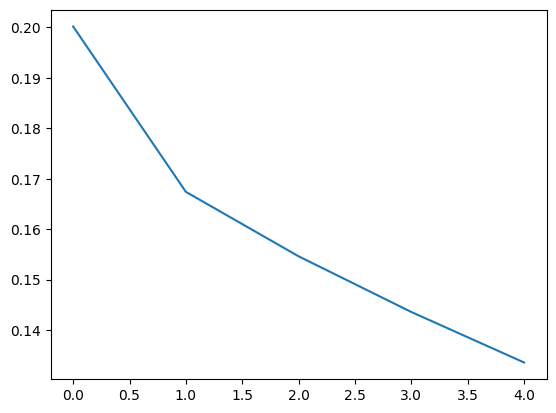

In [30]:
plt.plot(training_loss)

# save

In [42]:
manager = WeightManager(artifact_path.joinpath("gated_conv.{key}.pth").as_posix())

In [45]:
model_path = manager.get_filename(key=model.stage_configs)
model_path

WindowsPath('../../artifacts/gated_conv/gated_conv.((1, (900,), (4,)), (7, (900,), (4,))).pth')

In [46]:
manager.save_weight(model.state_dict(), model_path)

Save weight to ..\..\artifacts\gated_conv\gated_conv.((1, (900,), (4,)), (7, (900,), (4,))).pth, model size is 273.0MiB


In [21]:
manager.load_weight(model_path, model)

# Evaluation


In [31]:
val_dataset = load_dataset(
    "Salesforce/wikitext", name=DATASET_NAME, cache_dir=data_path, split="validation"
)

In [32]:
val_dataset = dataset_factory(
    val_dataset,
    MINIMUM_LENGTH,
    text_transform,
)

In [33]:
val_dataloader = DataLoader(
    val_dataset.with_format("torch"),
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    shuffle=True,
    collate_fn=collate_fn,
)

## predict next token

In [34]:
metric = Perplexity(ignore_index=CONTEXT.padding_idx).to(DEVICE)

In [ ]:
evaluator = RegressionEvaluator(DEVICE, feature_dim=-1)
# use this line when the head is conv1d
# 2x evaluation time, 0.9x training time XDD
evaluator.feature_last = True

In [45]:
evaluator.run(val_dataloader, model, metric=metric)

100%|██████████| 58/58 [00:53<00:00,  1.08it/s]


Perplexity()

In [ ]:
# epoch 5, kaiming, conv1d: 211
metric.compute()

tensor(211.8825, device='cuda:0')

In [ ]:
# epoch 5: 220
# epoch 5, kaiming: 215
metric.compute()

tensor(215.3351, device='cuda:0')

In [ ]:
tokens = tokenizer("Where are you going?")
sample = torch.Tensor(vocab.lookup_indices(tokens))[None, :].long().to(DEVICE)

model.eval()
with torch.no_grad():
    pred = model(sample[:, :-1])
    pred = pred.argmax(-1)
    pred = pred.tolist()[0]
    pred = vocab.lookup_tokens(pred)

for i, p in enumerate(pred):
    print(tokens[: i + 1], p)

['where'] he
['where', 'are'] known
['where', 'are', 'you'] satisfied
['where', 'are', 'you', 'going'] to


## free generation

In [40]:
# # from torchlake.common.utils.sequence import get_input_sequence

# model.eval()
# with torch.no_grad():
#     # primer = get_input_sequence((10, 1), CONTEXT)
#     # random_primer = torch.randint_like(primer, 0, VOCAB_SIZE)
#     # primer = torch.cat((primer, random_primer), 1)
#     primer = torch.randint(0, VOCAB_SIZE, (10, 1), device=DEVICE)

#     for _ in range(CONTEXT.max_seq_len):
#         pred = model(primer)

#     for it in pred:
#         line = it.tolist()
#         # try:
#         #     s = line.index(CONTEXT.bos_idx)
#         # except:
#         s = 0
#         try:
#             e = line.index(CONTEXT.eos_idx)
#         except:
#             e = -1
#         line = vocab.lookup_tokens(line)
#         print(" ".join(line[s:e]))

## word analogy


In [49]:
from torchlake.language_model.datasets import WordAnalogyDataset

In [50]:
analogy_data_path = Path("../../data") / "word-analogy"

In [51]:
dataset = WordAnalogyDataset(analogy_data_path)

In [52]:
dataset.data[:20]

[('Athens', 'Greece', 'Baghdad', 'Iraq'),
 ('Athens', 'Greece', 'Bangkok', 'Thailand'),
 ('Athens', 'Greece', 'Beijing', 'China'),
 ('Athens', 'Greece', 'Berlin', 'Germany'),
 ('Athens', 'Greece', 'Bern', 'Switzerland'),
 ('Athens', 'Greece', 'Cairo', 'Egypt'),
 ('Athens', 'Greece', 'Canberra', 'Australia'),
 ('Athens', 'Greece', 'Hanoi', 'Vietnam'),
 ('Athens', 'Greece', 'Havana', 'Cuba'),
 ('Athens', 'Greece', 'Helsinki', 'Finland'),
 ('Athens', 'Greece', 'Islamabad', 'Pakistan'),
 ('Athens', 'Greece', 'Kabul', 'Afghanistan'),
 ('Athens', 'Greece', 'London', 'England'),
 ('Athens', 'Greece', 'Madrid', 'Spain'),
 ('Athens', 'Greece', 'Moscow', 'Russia'),
 ('Athens', 'Greece', 'Oslo', 'Norway'),
 ('Athens', 'Greece', 'Ottawa', 'Canada'),
 ('Athens', 'Greece', 'Paris', 'France'),
 ('Athens', 'Greece', 'Rome', 'Italy'),
 ('Athens', 'Greece', 'Stockholm', 'Sweden')]

In [53]:
tokens = [[vocab[word.lower()] for word in pairs] for pairs in dataset.data]
tokens = torch.LongTensor([token for token in tokens if len(token) == 4])
tokens[:10]

tensor([[13188,  7030, 18709,  5345],
        [13188,  7030,  9110,  6531],
        [13188,  7030, 10409,  1348],
        [13188,  7030,  4715,  1273],
        [13188,  7030,     0,  4431],
        [13188,  7030, 14278,  2287],
        [13188,  7030, 16955,   481],
        [13188,  7030, 14582,  1553],
        [13188,  7030, 17430,  6426],
        [13188,  7030,     0,  6623]])

In [ ]:
model.eval()
with torch.no_grad():
    # embedder = model.input_embedding.to("cpu")
    embedder = model.output_embedding
    embedder.eval()
    vectors = embedder(tokens)

In [59]:
vectors.shape

torch.Size([19544, 4, 900])

In [60]:
# input: 0.07
# output: 0.29
metric = nn.CosineSimilarity()

country_a, capital_a, country_b, capital_b = vectors.transpose(0, 1)
score = metric(country_a - capital_a - country_b, -capital_b)
print(score.mean().item())

0.29223448038101196
